In [1]:
#This part will be the setup and data loading here I will gonna import and called the data 

#Importing all the libraries that im going to use to visualize the data 
#pip install pandas openpyxl matplotlib seaborn plotly 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
import plotly.express as px 


In [2]:
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

In [3]:
DATA_FILE = "all_data_M_2023.xlsx"   
raw = pd.read_excel(DATA_FILE, dtype=str)
raw.shape

(413327, 32)

In [4]:
#Cleaning data proccess
NUM_COLS = ["TOT_EMP","EMP_PRSE","JOBS_1000","LOC_QUOTIENT","PCT_TOTAL","H_MEAN","A_MEAN",
            "A_PCT10","A_PCT25","A_MEDIAN","A_PCT75","A_PCT90"]
df = raw.copy()
for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c].str.replace(",", ""), errors="coerce")

# Rows we will reuse.  AREA_TYPE: 1 = national, 2 = state, 4 = metropolitan area
national = df[(df.AREA_TYPE=="1") & (df.I_GROUP=="cross-industry") & (df.OWN_CODE=="1235")]
states   = df[(df.AREA_TYPE=="2") & (df.I_GROUP=="cross-industry")]
metros   = df[(df.AREA_TYPE=="4") & (df.I_GROUP=="cross-industry")]
print(len(national), len(states), len(metros))

1403 36643 149591


In [5]:
FOCUS = {
    "15-1221": ("Computer & Info Research Scientists", "AI / Research"),
    "15-2051": ("Data Scientists",                    "Data Science"),
    "15-2041": ("Statisticians",                      "Data Science"),
    "15-2031": ("Operations Research Analysts",       "Data Science"),
    "15-1243": ("Database Architects",                "Data Science"),
    "15-1252": ("Software Developers",                "Software Development"),
    "15-1253": ("Software QA Analysts & Testers",     "Software Development"),
    "15-1254": ("Web Developers",                     "Software Development"),
}
GROUP_COLORS = {"AI / Research":"#d1495b", "Data Science":"#2e86ab", "Software Development":"#7a9e3b"}

nat = national[national.OCC_CODE.isin(FOCUS)].copy()
nat["Occupation"] = nat.OCC_CODE.map(lambda c: FOCUS[c][0])
nat["Group"]      = nat.OCC_CODE.map(lambda c: FOCUS[c][1])
nat[["OCC_CODE","Occupation","Group","TOT_EMP","A_MEDIAN","A_MEAN","A_PCT10","A_PCT90"]].sort_values("TOT_EMP", ascending=False)

,OCC_CODE,Occupation,Group,TOT_EMP,A_MEDIAN,A_MEAN,A_PCT10,A_PCT90
149,15-1252,Software Developers,Software Development,1656880.0,132270.0,138110.0,77020.0,208620.0
150,15-1253,Software QA Analysts & Testers,Software Development,203040.0,101800.0,108460.0,58740.0,164520.0
165,15-2051,Data Scientists,Data Science,192710.0,108020.0,119040.0,61070.0,184090.0
161,15-2031,Operations Research Analysts,Data Science,117880.0,83640.0,95600.0,52930.0,148920.0
151,15-1254,Web Developers,Software Development,85350.0,84960.0,95570.0,46850.0,157280.0
145,15-1243,Database Architects,Data Science,59920.0,134700.0,137030.0,76000.0,194960.0
138,15-1221,Computer & Info Research Scientists,AI / Research,35210.0,145080.0,157160.0,81450.0,233110.0
163,15-2041,Statisticians,Data Science,29950.0,104110.0,109190.0,58690.0,163360.0


**Objective:**

The type of the first chart is comparison.
The aim of this chart is to compare the people in US who are working in Data Science and Sofware Ocupation 

## Visualisation 1 – Horizontal bar chart ##
I use a horizontal bar chart because the data is one categorical variable (occupation only) + one numerical variable (TOT_EMP).
The bars are the standard choice to compare a number accross categories.

Another thing is because the occupation names are way too long and this way stay readables on the y-axis.
Bars are sorted by size, so the ranking is clear at a glance.

**What I learned:**
Software Developers are 1656880.0, like about the 70% of the total 8 ocupations, more than all other combined.
Software QA Analysts & Testers are 203040.0 and the Data Scientists 192710.0 are 2nd and 3rd  place, each about the 8%.
Computer & Info Research Scientists	this occupation closest to AI research, number only 35210.0	about the 1.5% like 47 times fewer than the software developers.
Statisticians are at 29950.0 as the smallest group here.
    
**Why I use this chart:**
I chose a horizontal bar chart because I had 88 categories with very different sizes so if I use a pie chart it would be really hard to compare the small slices since they are gonna be barely visible

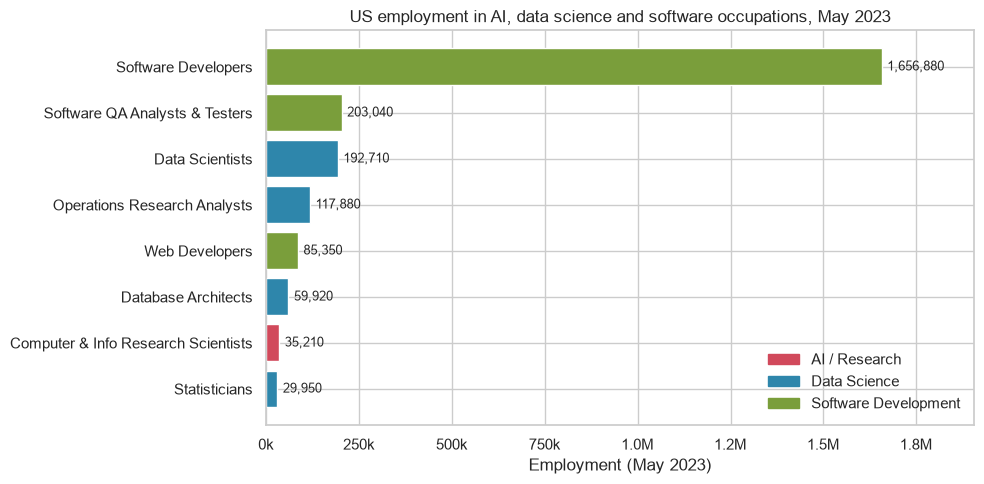

Occupation
Software Developers                    69.6
Software QA Analysts & Testers          8.5
Data Scientists                         8.1
Operations Research Analysts            5.0
Web Developers                          3.6
Database Architects                     2.5
Computer & Info Research Scientists     1.5
Statisticians                           1.3
Name: TOT_EMP, dtype: float64

In [7]:
d = nat.sort_values("TOT_EMP")
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(d.Occupation, d.TOT_EMP, color=d.Group.map(GROUP_COLORS))
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in d.TOT_EMP], padding=4, fontsize=9)
ax.set_xlabel("Employment (May 2023)")
ax.set_title("US employment in AI, data science and software occupations, May 2023")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}k"))
ax.set_xlim(0, d.TOT_EMP.max() * 1.15)
handles = [plt.Rectangle((0,0),1,1,color=c) for c in GROUP_COLORS.values()]
ax.legend(handles, GROUP_COLORS.keys(), loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

share = nat.set_index("Occupation").TOT_EMP / nat.TOT_EMP.sum() * 100
share.round(1).sort_values(ascending=False)

**Objective:**
The aim here is to comparing distributions, not just averages.

## Visualisation 1 – Box plot ##

**What I learned:**
Research scientists have the highest median pay, 145,080, about 3 times the US median of 48,060.
Even the lowest-paid 10% in most of these jobs earn more than a typical US worker. Web developers are the only exception.
Data scientists’ median is 108,020, about $24k below software developers, but their pay range is wider.

**Why I use this chart:**
the dataset gives the 10th, 25th, 50th, 75th and 90th percentiles of annual wage, which are exactly what a box plot draws.